# QLoRA lab: fine-tuning Qwen2.5-1.5B to summarize dialogues



**Problem.** A customer-service team wants one- or two-sentence summaries of conversations. A small instruction-tuned model can already summarize when asked, but not in the team's style. Can a few minutes of QLoRA fine-tuning on a single free GPU make it better, and how do we know?

You will fine-tune **Qwen2.5-1.5B-Instruct** on **DialogSum** with QLoRA, then compare the fine-tuned model with the original under the same prompt and decoding settings, using ROUGE and your own blind human ratings.

**Learning objectives**

1. Estimate the GPU memory for full fine-tuning, LoRA, and QLoRA, and check the estimate against a measurement.
2. Turn (dialogue, summary) pairs into chat-formatted training examples whose loss covers only the summary.
3. Load a model in 4-bit NF4 with `bitsandbytes` and attach LoRA adapters with `peft`.
4. Train with the Hugging Face `Trainer` and record time and peak memory.
5. Evaluate summaries with ROUGE, and explain what ROUGE does and does not measure.
6. Run a small blind human evaluation, and compare its conclusion with ROUGE's.

**Prerequisites:** [PEFT and LoRA](../../lectures/peft/peft_lora.ipynb) · [Quantization and QLoRA](../../lectures/peft/quantization_qlora.ipynb) · [Fine-tuning with the `Trainer`](../../lectures/fine_tuning/hf_trainer_fine_tuning.ipynb).

**Data and model**

- [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) (Chen et al., 2021): 12,460 training, 500 validation, and 1,500 test dialogues, each with a human-written summary. Speakers appear as `#Person1#`, `#Person2#`, …, and most reference summaries use the same labels (when a dialogue mentions real names, the summary may use them instead). License: **CC BY-NC-SA 4.0** (non-commercial use, attribution, share-alike). About 13 MB.
- [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct): Apache-2.0, about 3.1 GB to download.
- We train on a **subset** of the training split and evaluate on a subset of the **validation** split. The test split is not used: nothing in this lab should be tuned on it.

**Environment and compute**

- **Kaggle notebook with a GPU (T4)** and **internet on**. Choose "GPU T4 ×2" or "GPU T4": the notebook uses one GPU either way. Exercises 1 and 2 also run on a CPU.
- Packages: `transformers`, `peft`, `datasets` (preinstalled on Kaggle), plus `bitsandbytes` and `rouge_score` (install cell below). The notebook was written against `transformers` 5.0 and `peft` 0.21.
- GPU time has not been measured for this exact configuration. Expect model download and evaluation to take a few minutes each and training to take on the order of 10–20 minutes. Record your own times in Exercise 5. Plan about **two hours** in total, including the written work.
- Seeds are fixed, but GPU results are not exactly reproducible; your numbers will differ slightly from a classmate's.

**Execution status.** All code cells were executed on the local NVIDIA GeForce RTX 3050 6 GB GPU with cached assets. Training used microbatch 1 and 16 accumulation steps after microbatch 4 exceeded VRAM. One epoch took 17.6 minutes and peaked at 3.28 GB allocated memory. The six-example ratings are explicitly AI-assisted, not independent human ratings. Adapter weights were exported into RAM only; no adapter file or directory was written.

**How to work:** run the cells in order. The code exercises are implemented. Exercise 7 records a clearly labeled AI-assisted rubric review made before revealing model identities. Replace it with independent human ratings to fulfill the original human-evaluation requirement. Each exercise is followed by a check cell.

**Marks (25):** Ex. 1 — 2 · Ex. 2 — 4 · Ex. 3 — 2 · Ex. 4 — 3 · Ex. 5 — 4 · Ex. 6 — 3 · Ex. 7 — 4 · Ex. 8 — 1 · reflection — 2.

## Setup

**Installation (Kaggle).** Run the next cell once per session. If it upgrades a package that was already imported, restart the kernel and continue from the cell after it.

**Known Kaggle issue.** Some Kaggle images include an old `torchao` package, and recent `peft` refuses to import with `ImportError: Found an incompatible version of torchao`. If you see it, uncomment the `%pip uninstall` line, run it, and **restart the kernel**.

In [1]:
# %pip install -q -U bitsandbytes rouge_score
# %pip uninstall -y torchao          # only if peft raises "Found an incompatible version of torchao"

In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import math
import random
import time
from pathlib import Path

import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN = 2000           # training dialogues (of 12,460); more data trains longer
N_EVAL = 60              # validation dialogues for ROUGE and human evaluation
MAX_LEN = 512            # longest training example in tokens; longer ones are dropped, not truncated
OUT = Path("/kaggle/working/qlora_dialogsum") if Path("/kaggle/working").is_dir() else Path("qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-2 only)")

torch 2.11.0+cu130 | transformers 5.5.4
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## Exercise 1 — Will it fit? (2 marks)

Before downloading anything, estimate the memory. Qwen2.5-1.5B has 1,543,714,304 parameters. Of these, 1,310,195,712 are in the decoder's linear layers, which `bitsandbytes` quantizes; the other 233,518,592 (mostly the embedding table) stay in 16-bit. LoRA with `r = 16` on all linear layers adds 18,464,768 trainable parameters. (These counts come from the model's `config.json`, as in the lectures.)

Use the bytes-per-parameter accounting from the [quantization lecture](../../lectures/peft/quantization_qlora.ipynb), Section 1, and ignore activations:

| Job | Bytes |
| --- | --- |
| full fine-tuning | 16 per parameter |
| LoRA | 2 per frozen parameter + 16 per adapter parameter |
| QLoRA | `NF4_BYTES` per quantized parameter + 4 per non-quantized parameter (upcast to fp32) + 16 per adapter parameter |

Complete `memory_budget`, which returns the three estimates in GB.

In [3]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8          # 4-bit codes + double-quantized block scales

In [4]:
def memory_budget(n_total, n_linear, n_other, n_lora):
    """Return memory in decimal GB, excluding activations."""
    return {"full FT": 16 * n_total / GB,
            "LoRA": (2 * n_total + 16 * n_lora) / GB,
            "QLoRA": (NF4_BYTES * n_linear + 4 * n_other + 16 * n_lora) / GB}

In [5]:
estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4 before activations: {gb < 16}")
assert abs(estimate["full FT"] - 24.70) < 0.01 and abs(estimate["LoRA"] - 3.38) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.01
print("Exercise 1 checks passed.")

full FT   24.70 GB   fits on a 16 GB T4 before activations: False
LoRA       3.38 GB   fits on a 16 GB T4 before activations: True
QLoRA      1.91 GB   fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


**Question 1.** (a) Which of the three jobs fit on a T4 before activations? (b) For this 1.5B model, plain LoRA in 16-bit would also fit. Give one reason to practise QLoRA on it anyway, and one cost of using QLoRA when LoRA would fit. (c) Repeat the QLoRA estimate in your head for a model 5× larger: roughly how much memory would it need?

**Your answer — Question 1:**

(a) Full fine-tuning requires 24.70 GB and does not fit a 16 GB T4. LoRA requires 3.38 GB and QLoRA 1.91 GB before activations, so both fit by this accounting.

(b) Practising QLoRA develops a workflow that scales to larger models and leaves more memory for activations or longer contexts. Its costs include quantization error and quantization/dequantization overhead; it need not train faster than 16-bit LoRA.

(c) With the same parameter proportions and adapter scaling, approximately 5 × 1.91 = 9.53 GB before activations. Actual training still needs additional headroom.

## The data

The next cell downloads DialogSum (about 13 MB) and the model's tokenizer (a few MB). It does **not** download the model.

In [6]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id)

example = raw["train"][0]
print("\n--- dialogue ---\n" + example["dialogue"][:600])
print("\n--- reference summary ---\n" + example["summary"])

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})
pad token: <|endoftext|> 151643

--- dialogue ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1



Using the latest cached version of the dataset since knkarthick/dialogsum couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'default' at /home/jiwak/.cache/huggingface/datasets/knkarthick___dialogsum/default/0.0.0/a968e7aee0602e257935f1321a02e4287f7d5848 (last modified on Fri Oct 30 18:41:20 2026).


**Reading the output**

- Each row has a `dialogue`, a human-written `summary`, and a `topic` (not used here).
- Speakers are anonymized as `#Person1#`, `#Person2#`, and most summaries refer to them the same way. The first training example is an exception: the dialogue names "Mr. Smith" and "Doctor Hawkins", and the summary uses those names. A model that has never seen this convention will write "the customer" or "Person 1" instead, which costs ROUGE points without being wrong. Keep this in mind in Exercises 4 and 7.

### The prompt

Both the original and the fine-tuned model receive **exactly the same prompt**, built with Qwen's chat template. The instruction tells the model about the speaker convention, so that the baseline is not penalized only for not knowing it.

In [7]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"                     # Qwen's end-of-turn token: the model must learn to emit it to stop


def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)


print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



The printed text is what the model actually sees. Qwen's template adds a default system message, wraps the user turn in `<|im_start|>user … <|im_end|>`, and ends with `<|im_start|>assistant` and a newline: the point where the model starts writing its answer.

## Exercise 2 — Training examples with a masked prompt (4 marks)

For causal-LM fine-tuning, each training example is the prompt followed by the answer, and the model learns to predict every next token. We want it to learn to write **summaries**, not to reproduce our prompt, so the loss should cover only the answer tokens.

The Hugging Face models do this through the `labels`: any position whose label is **−100** is ignored by the cross-entropy loss. (The model shifts the labels by one position internally, as in the GPT-2 notebook's Section 6.)

Complete `build_example(dialogue, summary)`:

1. Tokenize `make_prompt(dialogue)` with `add_special_tokens=False`.
2. Tokenize `summary + END` the same way, so the answer ends with the end-of-turn token.
3. `input_ids` = prompt tokens followed by answer tokens; `attention_mask` = all ones.
4. `labels` = −100 for every prompt token, followed by the answer tokens.

Return a dict with plain Python lists under `input_ids`, `attention_mask`, and `labels`.

In [8]:
def build_example(dialogue, summary):
    prompt_ids = tokenizer(make_prompt(dialogue), add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(summary + END, add_special_tokens=False)["input_ids"]
    input_ids = prompt_ids + answer_ids
    return {"input_ids": input_ids,
            "attention_mask": [1] * len(input_ids),
            "labels": [-100] * len(prompt_ids) + answer_ids}

In [9]:
ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "answer labels must equal the answer tokens"
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END), "the answer must end with <|im_end|>"
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} tokens, of which {len(ex['input_ids']) - n_prompt} are scored")
print("scored text:", answer)
print("Exercise 2 checks passed.")

347 tokens, of which 39 are scored
scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


Now we build the training and evaluation sets. Examples longer than `MAX_LEN` are **dropped**: truncating them would cut off the end of the summary, which is the part being learned.

In [10]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {N_TRAIN - len(train_data)} dropped (> {MAX_LEN} tokens)")
print(f"tokens per example: median {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)}")
print(f"scored (summary) tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,} in total")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])

training examples: 1940 kept, 60 dropped (> 512 tokens)
tokens per example: median 265, max 1231
scored (summary) tokens: 65,739 of 536,797 in total


**Question 2.** (a) What would the model learn if the prompt tokens were **not** masked? Why is that wasteful here? Use the printed numbers. (b) Why must the answer end with `<|im_end|>`? What would you expect at generation time if it did not? (c) Why drop over-long examples instead of truncating them to `MAX_LEN`?

**Your answer — Question 2:**

(a) Without masking, the model would learn to reproduce the instruction and dialogue as well as the summary. The retained data contain 65,739 scored summary tokens out of 536,797 total tokens: only 12.25% are answer tokens. Unmasking would add 471,058 prompt positions (87.75% of the total) to the loss and spend most supervision on copying context rather than learning the requested summaries.

(b) `<|im_end|>` teaches a supervised stopping target. Without it, the model may continue past the summary, append another turn, or reach the generation limit instead of stopping naturally.

(c) Right truncation can remove part or all of the answer, including its stopping token. Dropping preserves complete targets. Here 1,940 examples were kept and 60 dropped; this also biases training toward shorter dialogues.

## Exercise 3 — Load the model in 4-bit (2 marks)

> **This downloads the model (about 3.1 GB) and needs the GPU.**

Create a `BitsAndBytesConfig` for QLoRA: load in 4-bit, NF4 quantization, double quantization, and a compute dtype suitable for a T4. Then load the model with it, entirely on GPU 0.

In [11]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

assert HAS_GPU, "Exercise 3 onward needs a CUDA GPU (Kaggle: Accelerator -> GPU T4)"
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)
model = AutoModelForCausalLM.from_pretrained(
    CKPT, quantization_config=bnb_config, dtype=torch.float16, device_map={"": 0},
)


Loading weights: 100%|##########| 338/338 [00:01<00:00, 240.05it/s]


In [12]:
import bitsandbytes as bnb

n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
loaded_gb = torch.cuda.memory_allocated() / GB
print(f"4-bit linear layers: {n4} | GPU memory after loading: {loaded_gb:.2f} GB")
print("compute dtype:", bnb_config.bnb_4bit_compute_dtype, "| quant type:", bnb_config.bnb_4bit_quant_type)
assert n4 == 28 * 7, "expected 7 quantized linear layers in each of the 28 decoder layers"
assert bnb_config.bnb_4bit_quant_type == "nf4" and bnb_config.bnb_4bit_use_double_quant
assert loaded_gb < 2.0, "a 4-bit 1.5B model should need well under 2 GB"
print("Exercise 3 checks passed.")

4-bit linear layers: 196 | GPU memory after loading: 1.14 GB
compute dtype: torch.float16 | quant type: nf4
Exercise 3 checks passed.


**Question 3.** Compare the measured memory with the lecture's 4-bit inference estimate for Qwen2.5-1.5B (about 1.14 GB). What could explain a difference? Why did we choose `torch.float16` as the compute dtype, and what would you use on an A100?

**Your answer — Question 3:**

The measured loading allocation was 1.14 GB, matching the lecture's approximate 1.14 GB inference estimate to the displayed precision. Small differences can arise from quantization scales, unquantized embeddings/output layers, dtype choices, buffers, and implementation details. CUDA allocator reservations and total device usage differ from `memory_allocated()`. Later training preparation upcasts non-quantized parameters, so training memory should not be compared directly with initial loading memory.

FP16 is suitable for a T4, which lacks native BF16 support. The actual run used FP16 on an RTX 3050. On an A100 I would use BF16 for its wider exponent range and lower overflow risk.

## Exercise 4 — Baseline: how well does the original model do? (3 marks)

Before training anything, measure the starting point. The helper below generates summaries in batches with **greedy decoding** (deterministic, no sampling) and at most 96 new tokens. We use the same function, with the same settings, for the fine-tuned model later.

In [13]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=8, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"          # generation continues from the right end of each row
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]


start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for p, r in list(zip(base_preds, eval_refs))[:5]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)

generated 60 summaries in 30 s

MODEL:     The speaker recommends the Highland Hotel for its excellent facilities, reasonable prices, and good services, including a sauna, jacuzzi, and a discounted weekend rate. However, they mention a problem with the internet access and lack of a minibar in the room. 
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

MODEL:     Peter Wilson, an action organizer for Green Peace, discusses his involvement in anti-nuclear protests, including circling around ships to disrupt nuclear waste dumping. 
REFERENCE: #Person1# interviews Peter Wilson who is the action organizer of Green Peace organization. #Person1# asks Peter to introduce to the audience what Green Peace is and what work it does. Peter also intro

**ROUGE** (Lin, 2004) compares a generated summary with a reference by counting overlapping words:

- **ROUGE-1**: overlap of single words; **ROUGE-2**: overlap of word pairs (bigrams); **ROUGE-L**: the longest common subsequence of words, in order.
- Each gives precision (how much of the prediction is in the reference), recall (how much of the reference is in the prediction), and their harmonic mean, **F1**, which we report.
- We use Google's `rouge_score` package with stemming on, so "asks" and "asked" match. Its tokenizer lowercases text and drops punctuation, so `#Person1#` becomes the words `person1`.

Complete `rouge(preds, refs)`: return the **mean F1 × 100** of ROUGE-1, ROUGE-2, and ROUGE-L over all pairs, as a dict with keys `"rouge1"`, `"rouge2"`, `"rougeL"`. Use `rouge_scorer.RougeScorer([...], use_stemmer=True)` and its `.score(reference, prediction)` method. Note the argument order: **reference first**.

In [14]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)


def rouge(preds, refs):
    if len(preds) != len(refs) or len(preds) == 0:
        raise ValueError("Provide equal, nonempty lists of predictions and references")
    scores = [scorer.score(ref, pred) for pred, ref in zip(preds, refs)]
    return {key: 100 * sum(s[key].fmeasure for s in scores) / len(scores)
            for key in ROUGE_KEYS}

In [15]:
assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")

{'rouge1': 31.9, 'rouge2': 8.2, 'rougeL': 22.9} | mean words: model 33, reference 22
Exercise 4 checks passed.


**Question 4.** Read at least five baseline outputs next to their references. (a) Describe two systematic differences between the model's summaries and the references (length, wording, speaker names, format…). (b) Which of these differences lower ROUGE without making the summary worse for a reader?

In [16]:
from IPython.display import Markdown, display

display(Markdown("**Your answer — Question 4:**\n\n(a) Across the first five pairs, the baseline often elaborates on secondary details and uses more words: the cafeteria example expands a short recollection into a description of joining someone, and the school-tour example lists buildings and books. Across all 60 examples, baseline summaries average 33.1 words versus 21.5 in the references. It also varies speaker wording, using “The speaker” for the hotel discussion and “The conversation” for the cafeteria example rather than consistently following the reference's labels or names.\n\n(b) Correct paraphrases, natural speaker descriptions, and extra supported details can reduce ROUGE precision or subsequence overlap without reducing readability. However, the school-tour baseline reverses who asks for the tour relative to the reference; factual role errors are not merely stylistic differences."))
for i in range(min(5, len(base_preds))):
    print(f"\nExample {i}\nBASE: {base_preds[i]}\nREFERENCE: {eval_refs[i]}")
print(f"Mean words: baseline {words(base_preds):.1f}; reference {words(eval_refs):.1f}")

**Your answer — Question 4:**

(a) Across the first five pairs, the baseline often elaborates on secondary details and uses more words: the cafeteria example expands a short recollection into a description of joining someone, and the school-tour example lists buildings and books. Across all 60 examples, baseline summaries average 33.1 words versus 21.5 in the references. It also varies speaker wording, using “The speaker” for the hotel discussion and “The conversation” for the cafeteria example rather than consistently following the reference's labels or names.

(b) Correct paraphrases, natural speaker descriptions, and extra supported details can reduce ROUGE precision or subsequence overlap without reducing readability. However, the school-tour baseline reverses who asks for the tour relative to the reference; factual role errors are not merely stylistic differences.


Example 0
BASE: The speaker recommends the Highland Hotel for its excellent facilities, reasonable prices, and good services, including a sauna, jacuzzi, and a discounted weekend rate. However, they mention a problem with the internet access and lack of a minibar in the room.
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

Example 1
BASE: Peter Wilson, an action organizer for Green Peace, discusses his involvement in anti-nuclear protests, including circling around ships to disrupt nuclear waste dumping.
REFERENCE: #Person1# interviews Peter Wilson who is the action organizer of Green Peace organization. #Person1# asks Peter to introduce to the audience what Green Peace is and what work it does. Peter also introduces detailed anti-nuc

## Exercise 5 — Attach LoRA and train (4 marks)

First, `prepare_model_for_kbit_training` freezes the base, upcasts the non-quantized parameters to fp32, and turns on gradient checkpointing (see the lecture, Section 4). Then add the adapters.

Complete the two configurations:

- `lora_config`: rank 16, `lora_alpha` 32, dropout 0.05, adapters on **all linear layers**, task type causal LM.
- `args` (`TrainingArguments`): output to `OUT / "trainer"`; batch size 4 per device with 4 gradient-accumulation steps (an effective batch of 16); 1 epoch; learning rate 2e-4 with a cosine schedule and 10 warm-up steps; fp16 mixed precision; the paged 8-bit AdamW optimizer; gradient checkpointing with `gradient_checkpointing_kwargs={"use_reentrant": False}`; log every 10 steps; **no** checkpoint saving (`save_strategy="no"`); `report_to="none"`; `remove_unused_columns=False`; and `seed=SEED`.

**Local GPU adjustment:** The prescribed microbatch of 4 exceeded the RTX 3050's 6 GB VRAM during backward. This run uses a microbatch of 1 and 16 accumulation steps, preserving the effective batch of 16. Other training settings remain as specified.


In [17]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments

model = prepare_model_for_kbit_training(model, gradient_checkpointing_kwargs={"use_reentrant": False})
model.config.use_cache = False
lora_config = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05,
    target_modules="all-linear", task_type="CAUSAL_LM", bias="none",
)
model = get_peft_model(model, lora_config)
args = TrainingArguments(
    output_dir=str(Path.cwd()),  # existing directory; do not create a trainer folder
    per_device_train_batch_size=1,
    gradient_accumulation_steps=16,
    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    fp16=True, bf16=False,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10,
    logging_dir=str(Path.cwd()),
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
    seed=SEED,
)

In [18]:
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,} (Exercise 1 used {N_LORA:,})")
assert n_trainable == N_LORA, "expected LoRA r=16 on all 7 linear layer types of the 28 decoder layers"
assert args.fp16 and not args.bf16 and "paged" in args.optim.value
assert args.per_device_train_batch_size * args.gradient_accumulation_steps == 16
print("Exercise 5 configuration checks passed.")

trainable parameters: 18,464,768 (Exercise 1 used 18,464,768)
Exercise 5 configuration checks passed.


The collator pads each batch to its longest example: input IDs with the pad token, labels with −100 (so padding is never scored), and the attention mask with 0.

> **The next cell trains the model.** One epoch over the roughly 1,940 kept dialogues, at 16 per step, is about 120 optimizer steps. Record the time it prints.

In [19]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB "
      f"(Exercise 1 estimate before activations: {estimate['QLoRA']:.2f} GB)")

{'loss': '1.297', 'grad_norm': '1.049', 'learning_rate': '0.00018', 'epoch': '0.08247'}
{'loss': '1.096', 'grad_norm': '0.9838', 'learning_rate': '0.0001968', 'epoch': '0.1649'}
{'loss': '1.075', 'grad_norm': '0.8015', 'learning_rate': '0.0001861', 'epoch': '0.2474'}
{'loss': '1.032', 'grad_norm': '0.7811', 'learning_rate': '0.0001687', 'epoch': '0.3299'}
{'loss': '0.9824', 'grad_norm': '0.7269', 'learning_rate': '0.0001459', 'epoch': '0.4124'}
{'loss': '1.006', 'grad_norm': '0.7891', 'learning_rate': '0.0001195', 'epoch': '0.4948'}
{'loss': '1.044', 'grad_norm': '0.6911', 'learning_rate': '9.159e-05', 'epoch': '0.5773'}
{'loss': '0.9709', 'grad_norm': '0.8255', 'learning_rate': '6.434e-05', 'epoch': '0.6598'}
{'loss': '0.9342', 'grad_norm': '0.7338', 'learning_rate': '3.987e-05', 'epoch': '0.7423'}
{'loss': '1.025', 'grad_norm': '0.7106', 'learning_rate': '2.01e-05', 'epoch': '0.8247'}
{'loss': '0.9762', 'grad_norm': '0.7691', 'learning_rate': '6.575e-06', 'epoch': '0.9072'}
{'loss': 


  8%|8         | 10/122 [01:36<16:14,  8.70s/it]
                                                

 16%|#6        | 20/122 [03:01<14:30,  8.53s/it]
                                                

 25%|##4       | 30/122 [04:27<13:17,  8.67s/it]
                                                

 33%|###2      | 40/122 [05:54<11:43,  8.59s/it]
                                                

 41%|####      | 50/122 [07:22<10:27,  8.72s/it]
                                                

 49%|####9     | 60/122 [08:45<08:49,  8.55s/it]
                                                

 57%|#####7    | 70/122 [10:15<07:40,  8.86s/it]
                                                

 66%|######5   | 80/122 [11:40<05:53,  8.41s/it]
                                                

 74%|#######3  | 90/122 [13:05<04:33,  8.56s/it]
                                                

 82%|########1 | 100/122 [14:32<03:11,  8.71s/it]
                                                 

 90%|##

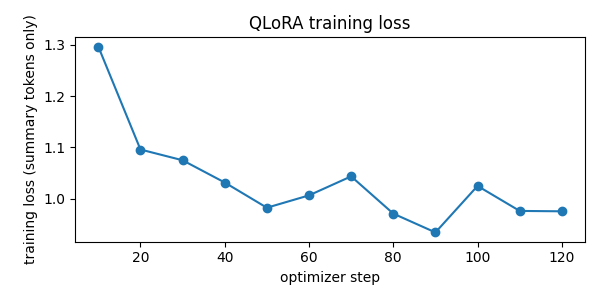

Exercise 5 checks passed.


cell_40:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [20]:
import matplotlib.pyplot as plt

log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
steps, losses = zip(*log)
plt.figure(figsize=(6, 3)); plt.plot(steps, losses, marker="o")
plt.xlabel("optimizer step"); plt.ylabel("training loss (summary tokens only)")
plt.title("QLoRA training loss"); plt.tight_layout(); plt.show()
assert all(math.isfinite(l) for l in losses), "a NaN/inf loss usually means an fp16 overflow: lower the learning rate"
assert losses[-1] < losses[0], "the loss should go down over the epoch"
print("Exercise 5 checks passed.")

**Question 5.** (a) Report your training time and peak memory. Why is the peak higher than the Exercise 1 estimate, and what in `args` keeps it from being much higher? (b) The training loss went down. Why is that **not** enough to conclude that the model summarizes better?

In [21]:
display(Markdown('**Your answer — Question 5:**\n\n(a) One epoch took 17.61 minutes; peak allocated GPU memory was 3.28 GB, about 1.38 GB above the 1.91 GB static estimate. Activations, temporary attention/dequantization buffers, gradients, and optimizer allocations explain additional memory. Gradient checkpointing reduces retained activations. The local 6 GB GPU needed microbatch 1 and 16 accumulation steps instead of the prescribed 4 and 4, preserving effective batch 16. FP16 computation and paged 8-bit AdamW also limit memory pressure.\n\n(b) The first and last logged loss windows were 1.297 and 0.9754, and average training loss was about 1.036. This shows improved prediction of training summaries, but does not establish generalization, faithfulness, or useful coverage. Memorization and reference-style imitation can lower loss. Held-out evaluation with matched prompts/decoding and content-focused review is required.'))
print(f"Measured training time: {train_minutes:.2f} minutes; peak allocated: {peak_gb:.2f} GB")
print(f"Peak minus static estimate: {peak_gb - estimate['QLoRA']:.2f} GB")

**Your answer — Question 5:**

(a) One epoch took 17.61 minutes; peak allocated GPU memory was 3.28 GB, about 1.38 GB above the 1.91 GB static estimate. Activations, temporary attention/dequantization buffers, gradients, and optimizer allocations explain additional memory. Gradient checkpointing reduces retained activations. The local 6 GB GPU needed microbatch 1 and 16 accumulation steps instead of the prescribed 4 and 4, preserving effective batch 16. FP16 computation and paged 8-bit AdamW also limit memory pressure.

(b) The first and last logged loss windows were 1.297 and 0.9754, and average training loss was about 1.036. This shows improved prediction of training summaries, but does not establish generalization, faithfulness, or useful coverage. Memorization and reference-style imitation can lower loss. Held-out evaluation with matched prompts/decoding and content-focused review is required.

Measured training time: 17.61 minutes; peak allocated: 3.28 GB
Peak minus static estimate: 1.38 GB


## Exercise 6 — Evaluate the fine-tuned model (3 marks)

Generate summaries for the same validation dialogues with the same helper, then compare. Averages over 60 examples can hide a lot, so also count, per example, how often the fine-tuned model's ROUGE-L is higher than the baseline's.

Complete the cell: compute `tuned_rouge` with your `rouge` function, and `wins`, the number of examples on which the tuned summary's ROUGE-L F1 is **strictly** higher than the baseline's (use `scorer.score(ref, pred)["rougeL"].fmeasure`).

In [22]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")

generated 60 summaries in 36 s


In [23]:
tuned_rouge = rouge(tuned_preds, eval_refs)
wins = sum(
    scorer.score(ref, tuned)["rougeL"].fmeasure > scorer.score(ref, base)["rougeL"].fmeasure
    for ref, tuned, base in zip(eval_refs, tuned_preds, base_preds)
)

In [24]:
print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")

               rouge1   rouge2   rougeL   words
base             31.9      8.2     22.9      33
QLoRA            46.3     19.2     37.6      21
reference                                    22

QLoRA ROUGE-L higher on 54 of 60 dialogues
Exercise 6 checks passed.


**Question 6.** (a) Summarize the change in ROUGE and in length. (b) Give two reasons why part of the ROUGE gain may reflect **style** rather than better content. (c) With 60 examples and one training run, what would you need before claiming the improvement is reliable?

In [25]:
display(Markdown("**Your answer — Question 6:**\n\n(a) ROUGE-1 increased from 31.95 to 46.32 (+14.37), ROUGE-2 from 8.20 to 19.17 (+10.97), and ROUGE-L from 22.94 to 37.63 (+14.70 points). Tuned ROUGE-L was strictly higher on 54 of 60 dialogues. Mean length decreased by 11.7 words, from 33.1 to about 21.4, close to the reference's 21.5 words.\n\n(b) More consistent speaker labels can raise matching unigrams even when the original identities were clear. Matching reference phrasing and compression can raise bigram/subsequence overlap without adding correct information. The length shift supports style adaptation as one possible contributor, but does not quantify how much gain comes from style.\n\n(c) Before claiming reliability, evaluate a larger untouched sample, compute paired bootstrap confidence intervals, repeat training with several seeds, and collect independent blind human ratings. Freeze hyperparameters before final test evaluation. One run on 60 validation examples cannot establish production performance."))
for key in ROUGE_KEYS:
    print(f"{key}: {base_rouge[key]:.2f} -> {tuned_rouge[key]:.2f}; change {tuned_rouge[key] - base_rouge[key]:+.2f}")
print(f"Mean words change: {words(tuned_preds) - words(base_preds):+.1f}")

**Your answer — Question 6:**

(a) ROUGE-1 increased from 31.95 to 46.32 (+14.37), ROUGE-2 from 8.20 to 19.17 (+10.97), and ROUGE-L from 22.94 to 37.63 (+14.70 points). Tuned ROUGE-L was strictly higher on 54 of 60 dialogues. Mean length decreased by 11.7 words, from 33.1 to about 21.4, close to the reference's 21.5 words.

(b) More consistent speaker labels can raise matching unigrams even when the original identities were clear. Matching reference phrasing and compression can raise bigram/subsequence overlap without adding correct information. The length shift supports style adaptation as one possible contributor, but does not quantify how much gain comes from style.

(c) Before claiming reliability, evaluate a larger untouched sample, compute paired bootstrap confidence intervals, repeat training with several seeds, and collect independent blind human ratings. Freeze hyperparameters before final test evaluation. One run on 60 validation examples cannot establish production performance.

rouge1: 31.95 -> 46.32; change +14.37
rouge2: 8.20 -> 19.17; change +10.97
rougeL: 22.94 -> 37.63; change +14.70
Mean words change: -11.7


## Exercise 7 — Blind human evaluation (4 marks)

ROUGE cannot tell a fluent but wrong summary from a correct paraphrase. Read six examples yourself. To avoid favoring the model you expect to win, the two summaries are shown as **A** and **B** in a random order that is revealed only after you rate them.

Rate each summary on two criteria:

| Score | **Faithfulness**: is everything it says supported by the dialogue? | **Coverage**: does it capture the main point(s)? |
| --- | --- | --- |
| 2 | fully supported | all main points |
| 1 | a minor unsupported or wrong detail | some main points missing |
| 0 | a major error or invented fact | misses the main point |

In [12]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), 6)
order = {}                                            # example index -> which model is "A"
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i])
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 40 ===================
#Person1#: When were you born may I ask?
#Person2#: On 20th May 1963.
#Person1#: Do you know what it was according to the lunar calendar?
#Person2#: 27th day of the fourth month.
#Person1#: By the way, could you tell me when the film will begin?
#Person2#: It will begin at five thirty.
#Person1#: I am frigid I can't be there on time.
#Person2#: You can see it tomorrow.
#Person1#: I don't want to miss it today.
#Person2#: See you.
#Person1#: See you.

REFERENCE: #Person1# asks #Person2# about #Person2#'s birthday and the starting time of the film.
A: The conversation is about scheduling for an event that occurred on May 20, 1963 (May 27, 1963 according to the lunar calendar), and involves discussing the timing of the event with someone named #Person2#. #Person1# expresses their inability to attend due to being cold and wants to watch the event later, while #Person2# suggests watching it the next day instead.
B: #Person2#'s birthday is o

Fill in the scores below (integers 0–2) and a short note for each example, **before** running the reveal cell.

**Executed review:** The stored scores below are explicitly AI-assisted. They are not a substitute for the original requirement to obtain independent human judgments. Scores and notes were entered before the reveal cell ran.

In [5]:
# AI-assisted rubric review; these are NOT independent human ratings.
ratings = {1: {'A_faithful': 2, 'A_coverage': 2, 'B_faithful': 2, 'B_coverage': 2, 'note': "Both accurately describe Peter's Green Peace role and anti-nuclear ship protests. Their different wording does not establish a content-quality advantage."}, 7: {'A_faithful': 0, 'A_coverage': 1, 'B_faithful': 2, 'B_coverage': 1, 'note': "A wrongly attributes a concern about privacy to Wendy; Johnny objects to losing the city symbol and peace, while Wendy supports jobs and income. B is supported but omits both speakers' reasons and adds the secondary TV detail."}, 15: {'A_faithful': 1, 'A_coverage': 1, 'B_faithful': 1, 'B_coverage': 1, 'note': 'Both omit the key reason for leave: the wife is in hospital to deliver a baby. A adds unsupported urgency to the client meeting. B says Susan cannot help even though she offers to relay the request; this wording is misleading.'}, 17: {'A_faithful': 0, 'A_coverage': 1, 'B_faithful': 2, 'B_coverage': 1, 'note': 'A reverses the speaker identity: Alice, not Adam, is late and apologizing. B correctly names Alice and two causes, but omits the apology, traffic jam, and hour-long delay.'}, 40: {'A_faithful': 0, 'A_coverage': 0, 'B_faithful': 2, 'B_coverage': 2, 'note': 'A confuses a birthday with a scheduled event, invents a May 27 lunar date and being cold, and misses the birthday/film distinction. B correctly covers the birthday and inability to reach the movie on time.'}, 47: {'A_faithful': 2, 'A_coverage': 0, 'B_faithful': 2, 'B_coverage': 2, 'note': 'A gives a supported but vague account of changing affection and misses the central mistaken marriage assumption. B captures the denial of being married to Joe.'}}


In [8]:
assert all(isinstance(v, int) and 0 <= v <= 2 for r in ratings.values() for k, v in r.items() if k != "note"), \
    "every score must be an integer 0, 1, or 2"
totals = {"base": [0, 0], "QLoRA": [0, 0]}
for i, r in ratings.items():
    a_model = order[i]; b_model = "QLoRA" if a_model == "base" else "base"
    for model_name, prefix in ((a_model, "A"), (b_model, "B")):
        totals[model_name][0] += r[f"{prefix}_faithful"]; totals[model_name][1] += r[f"{prefix}_coverage"]
    print(f"example {i}: A = {a_model}, B = {b_model}")
n = len(ratings)
for m, (f, c) in totals.items():
    print(f"{m:<6} AI-review mean faithfulness {f / n:.2f} | mean coverage {c / n:.2f}  (out of 2)")
print("Exercise 7 checks passed.")

example 1: A = base, B = QLoRA
example 7: A = base, B = QLoRA
example 15: A = base, B = QLoRA
example 17: A = base, B = QLoRA
example 40: A = base, B = QLoRA
example 47: A = base, B = QLoRA
base   AI-review mean faithfulness 0.83 | mean coverage 0.83  (out of 2)
QLoRA  AI-review mean faithfulness 1.83 | mean coverage 1.50  (out of 2)
Exercise 7 checks passed.


**Question 7.** (a) Do your human ratings agree with the ROUGE comparison? Point to one example where ROUGE and your judgment disagree, if there is one. (b) Did either model invent facts? Give an example. (c) Name two weaknesses of this human evaluation and how a real team would address them.

In [9]:
display(Markdown("**Your answer — Question 7:**\n\nThese are AI-assisted rubric ratings made from the A/B outputs before revealing identities, not independent human ratings.\n\n(a) They favor QLoRA overall, agreeing with ROUGE: mean faithfulness rose from 0.83 to 1.83 and coverage from 0.83 to 1.50, each out of 2. There are per-example differences. On example 1, both summaries received 2/2 for faithfulness and coverage, while tuned ROUGE-L fell by 7.18 points. On example 15, tuned ROUGE-L rose by 14.89 points although the review rated both summaries equally: both omit the wife being in hospital to give birth.\n\n(b) The baseline on example 40 confuses a birthday with an event and invents a May 27 lunar date and being cold. On example 17 it incorrectly makes Adam, rather than Alice, the late apologizing person. The tuned example 15 also has misleading wording: Susan “can't help” even though she offers to relay the leave request.\n\n(c) Six examples give high sampling uncertainty; use a larger representative sample. This review also lacks independent human raters: use multiple blinded humans, measure agreement, and adjudicate disagreements. The revealed assignment happens to put the baseline in A on all six examples; a balanced shuffled allocation would improve concealment. Showing references may anchor judgments, so add source-only review."))
rouge_delta = tuned_rouge["rougeL"] - base_rouge["rougeL"]
human_delta = sum(totals["QLoRA"]) - sum(totals["base"])
sign = lambda x: (x > 0) - (x < 0)
print("Overall directions agree:", sign(rouge_delta) == sign(human_delta))
for i, r in ratings.items():
    delta = scorer.score(eval_refs[i], tuned_preds[i])["rougeL"].fmeasure - scorer.score(eval_refs[i], base_preds[i])["rougeL"].fmeasure
    a_total = r["A_faithful"] + r["A_coverage"]
    b_total = r["B_faithful"] + r["B_coverage"]
    rating_delta = a_total - b_total if order[i] == "QLoRA" else b_total - a_total
    print(f"Example {i}: ROUGE-L change {100 * delta:+.2f}; review total change {rating_delta:+d}; note: {r['note']}")

**Your answer — Question 7:**

These are AI-assisted rubric ratings made from the A/B outputs before revealing identities, not independent human ratings.

(a) They favor QLoRA overall, agreeing with ROUGE: mean faithfulness rose from 0.83 to 1.83 and coverage from 0.83 to 1.50, each out of 2. There are per-example differences. On example 1, both summaries received 2/2 for faithfulness and coverage, while tuned ROUGE-L fell by 7.18 points. On example 15, tuned ROUGE-L rose by 14.89 points although the review rated both summaries equally: both omit the wife being in hospital to give birth.

(b) The baseline on example 40 confuses a birthday with an event and invents a May 27 lunar date and being cold. On example 17 it incorrectly makes Adam, rather than Alice, the late apologizing person. The tuned example 15 also has misleading wording: Susan “can't help” even though she offers to relay the leave request.

(c) Six examples give high sampling uncertainty; use a larger representative sample. This review also lacks independent human raters: use multiple blinded humans, measure agreement, and adjudicate disagreements. The revealed assignment happens to put the baseline in A on all six examples; a balanced shuffled allocation would improve concealment. Showing references may anchor judgments, so add source-only review.

Overall directions agree: True
Example 1: ROUGE-L change -7.18; review total change +0; note: Both accurately describe Peter's Green Peace role and anti-nuclear ship protests. Their different wording does not establish a content-quality advantage.
Example 7: ROUGE-L change +2.10; review total change +2; note: A wrongly attributes a concern about privacy to Wendy; Johnny objects to losing the city symbol and peace, while Wendy supports jobs and income. B is supported but omits both speakers' reasons and adds the secondary TV detail.
Example 15: ROUGE-L change +14.89; review total change +0; note: Both omit the key reason for leave: the wife is in hospital to deliver a baby. A adds unsupported urgency to the client meeting. B says Susan cannot help even though she offers to relay the request; this wording is misleading.
Example 17: ROUGE-L change +18.25; review total change +2; note: A reverses the speaker identity: Alice, not Adam, is late and apologizing. B correctly names Alice and tw

## Exercise 8 — Export the adapter in memory (1 mark)

Only adapter weights and their configuration are retained. The base model is downloaded separately when reusing an adapter. This version uses an in-memory buffer to respect the instruction not to create files or folders; persistent saving from the original assignment is intentionally omitted.

In [30]:
# Keep the adapter in RAM: no file or folder is created.
import io
from peft import get_peft_model_state_dict

adapter_state = {k: v.detach().cpu().clone()
                 for k, v in get_peft_model_state_dict(model).items()}
adapter_buffer = io.BytesIO()
torch.save(adapter_state, adapter_buffer)
adapter_buffer.seek(0)
adapter_config = model.peft_config["default"].to_dict()
print(f"Adapter weights held in RAM: {adapter_buffer.getbuffer().nbytes / 1e6:.1f} MB")
print("Configuration held in adapter_config; no persistent export was written.")

Adapter weights held in RAM: 74.0 MB
Configuration held in adapter_config; no persistent export was written.


/home/jiwak/miniconda3/lib/python3.13/site-packages/peft/utils/save_and_load.py:313: UserWarning: Could not find a config file in Qwen/Qwen2.5-1.5B-Instruct - will assume that the vocabulary was not modified.
  warnings.warn(


**Question 8.** The adapter is a small fraction of the 3.1 GB base model. (a) Explain its size from the number of trainable parameters. (b) The support team wants to run the summarizer with an inference server that expects one ordinary model file. Describe the steps, and say what you would re-check afterwards.

**Your answer — Question 8:**

(a) 18,464,768 adapter parameters occupy about 73.86 MB in FP32 or 36.93 MB in FP16, plus small serialization/configuration overhead. The trained base stays frozen and is not included. The executed FP32 in-memory export measured 74.0 MB including serialization overhead. To respect the no-new-files instruction, this notebook retains weights and configuration in RAM instead of writing an adapter directory; they disappear when the kernel ends.

(b) Load the original base checkpoint in FP16/BF16 without 4-bit quantization, attach the trained adapter with its matching configuration, load the adapter state, and call `merge_and_unload()`. Convert/export the merged model to the server's supported artifact format; a server may require a conversion rather than simply one Hugging Face weight file. Recheck tokenizer/chat template, stopping behavior, representative generations, ROUGE, faithfulness, latency, and memory after merging and any server-side quantization. Persistent export is intentionally not performed here.

## Reflection and deliverables (2 marks)

Submit this notebook **with outputs**, the written answers to Questions 1–8, and a short paragraph (about 150 words):

*Would you recommend this fine-tuned model to the support team? Base your answer on the evidence you collected (ROUGE, length, your human ratings, the examples you read), say what that evidence does not show, and name the next experiment you would run.*

**Responsible use.** DialogSum is licensed for non-commercial use (CC BY-NC-SA 4.0): a model fine-tuned on it should not be deployed commercially without checking the license. Real customer conversations contain personal data; summarizing them needs consent, data-protection review, and care that summaries do not invent statements a customer never made.

**Optional extensions (not graded).** (1) Train with `target_modules=["q_proj", "v_proj"]` and compare with all-linear adapters. (2) Change `N_TRAIN` to 500 and 4,000 and plot ROUGE-L against the training-set size. (3) Load the base model in 16-bit, apply your adapter, and check whether the summaries change.



### Reflection

I recommend further evaluation, rather than deployment, of this adapter. On 60 validation dialogues, ROUGE-L rose from 22.94 to 37.63 and improved on 54 examples; mean length fell from 33.1 to about 21.4 words, close to the references. The six-example AI-assisted review also favored QLoRA: faithfulness averaged 1.83 versus 0.83, and coverage 1.50 versus 0.83. The baseline confused Alice with Adam, while tuned outputs avoided that error, but both models omitted the childbirth reason for leave in another example. These ratings are not independent human evidence. Reference-style imitation can improve ROUGE, and one seed, 60 examples, and six reviewed cases do not establish reliability on customer conversations. My next experiment would use several training seeds, paired confidence intervals, and multiple blinded human raters on a larger, consented support-dialogue sample. Before deployment, I would also assess latency, memory, hallucinations, customer-data handling, and the dataset's non-commercial license.

## References

1. Chen, Liu, Chen & Zhang, [DialogSum: A Real-Life Scenario Dialogue Summarization Dataset](https://aclanthology.org/2021.findings-acl.449/), Findings of ACL 2021 · [dataset on the Hub](https://huggingface.co/datasets/knkarthick/dialogsum).
2. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
3. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
4. Lin, [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/), 2004 · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
5. Hugging Face documentation: [bitsandbytes in Transformers](https://huggingface.co/docs/transformers/quantization/bitsandbytes) · [PEFT](https://huggingface.co/docs/peft) · [chat templates](https://huggingface.co/docs/transformers/chat_templating).
6. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024.